# ML Assignment 2 – Classification Models + Streamlit App
**M.Tech AIML (WILP) – Machine Learning** · Shuban M S · 2026AJ05529

**Dataset:** UCI Online Shoppers Purchasing Intention (id 468) – predict whether a browsing session ends in a purchase (`Revenue`).

Run every cell top to bottom on **BITS Virtual Lab**. The notebook:
1. downloads and explores the dataset
2. trains & evaluates 5 classifiers (Accuracy, AUC, Precision, Recall, F1, MCC)
3. saves the models to `model/` and the test split to `test_data.csv`
4. writes `app.py`, `requirements.txt` and `README.md` for the GitHub repo

In [1]:
%pip install -q ucimlrepo


[notice] A new release of pip is available: 24.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, json, platform, getpass
from datetime import datetime

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, roc_auc_score, precision_score, recall_score,
                             f1_score, matthews_corrcoef, confusion_matrix, classification_report)

import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

SEED = 42
UCI_ID = 468
MODEL_DIR = "model"
DATA_DIR = "data"
LOCAL_CSV = os.path.join(DATA_DIR, "online_shoppers_intention.csv")
os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(DATA_DIR, exist_ok=True)

print("Run at      :", datetime.now().strftime("%d-%b-%Y %H:%M:%S"))
print("User / host :", getpass.getuser(), "@", platform.node())
print("Python      :", platform.python_version(), "| scikit-learn:", sklearn.__version__)

Run at      : 08-Nov-2026 20:31:59
User / host : s2026aj05529 @ ip-10-3-25-92.ap-south-1.compute.internal
Python      : 3.12.7 | scikit-learn: 1.9.0


## 2. Load dataset
Fetches from UCI with `ucimlrepo`. If the lab blocks the download, put the CSV from the UCI page at `data/online_shoppers_intention.csv` and re-run.

In [3]:
try:
    from ucimlrepo import fetch_ucirepo
    shoppers = fetch_ucirepo(id=UCI_ID)
    X_raw = shoppers.data.features
    y_raw = shoppers.data.targets
    TARGET = y_raw.columns[0]
    data = pd.concat([X_raw, y_raw[[TARGET]]], axis=1)
    data.to_csv(LOCAL_CSV, index=False)
    print("Downloaded from UCI ->", LOCAL_CSV)
    print(shoppers.metadata.get("name"))
    display(shoppers.variables)
except Exception as err:
    print("UCI download failed (", err, ") -> using local CSV")
    data = pd.read_csv(LOCAL_CSV)
    TARGET = "Revenue"

print("Shape:", data.shape)
data.head()

Downloaded from UCI -> data/online_shoppers_intention.csv
Online Shoppers Purchasing Intention Dataset


,name,role,type,demographic,description,units,missing_values
0,Administrative,Feature,Integer,None,None,None,no
1,Administrative_Duration,Feature,Integer,None,None,None,no
2,Informational,Feature,Integer,None,None,None,no
3,Informational_Duration,Feature,Integer,None,None,None,no
4,ProductRelated,Feature,Integer,None,None,None,no
5,ProductRelated_Duration,Feature,Continuous,None,None,None,no
6,BounceRates,Feature,Continuous,None,None,None,no
7,ExitRates,Feature,Continuous,None,None,None,no
8,PageValues,Feature,Integer,None,None,None,no
9,SpecialDay,Feature,Integer,None,None,None,no


Shape: (12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


## 3. Exploratory data analysis

In [4]:
features_all = [c for c in data.columns if c != TARGET]
print(f"Instances: {len(data)}  |  Features: {len(features_all)}")
assert len(features_all) >= 12 and len(data) >= 500, "Dataset does not meet size requirements"

print("\nMissing values per column:", int(data.isna().sum().sum()), "in total")
print("\nData types:")
print(data.dtypes.value_counts())
data.describe().T.round(3)

Instances: 12330  |  Features: 17

Missing values per column: 0 in total

Data types:
int64      7
float64    7
str        2
bool       2
Name: count, dtype: int64


,count,mean,std,min,25%,50%,75%,max
Administrative,12330.0,2.315,3.322,0.0,0.000,1.000,4.000,27.000
Administrative_Duration,12330.0,80.819,176.779,0.0,0.000,7.500,93.256,3398.750
Informational,12330.0,0.504,1.270,0.0,0.000,0.000,0.000,24.000
Informational_Duration,12330.0,34.472,140.749,0.0,0.000,0.000,0.000,2549.375
ProductRelated,12330.0,31.731,44.476,0.0,7.000,18.000,38.000,705.000
ProductRelated_Duration,12330.0,1194.746,1913.669,0.0,184.138,598.937,1464.157,63973.522
BounceRates,12330.0,0.022,0.048,0.0,0.000,0.003,0.017,0.200
ExitRates,12330.0,0.043,0.049,0.0,0.014,0.025,0.050,0.200
PageValues,12330.0,5.889,18.568,0.0,0.000,0.000,0.000,361.764
SpecialDay,12330.0,0.061,0.199,0.0,0.000,0.000,0.000,1.000


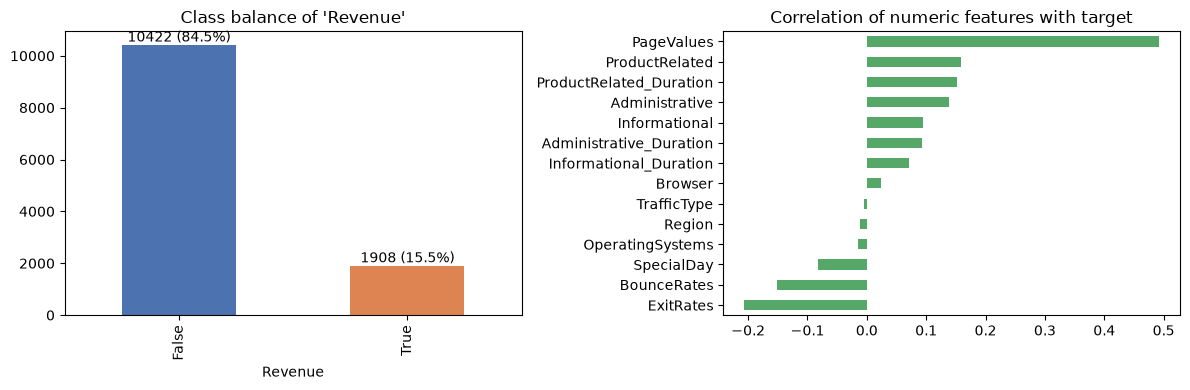

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
balance = data[TARGET].value_counts()
balance.plot.bar(ax=axes[0], color=["#4c72b0", "#dd8452"])
axes[0].set_title(f"Class balance of '{TARGET}'")
for i, v in enumerate(balance.values):
    axes[0].text(i, v, f"{v} ({v/len(data):.1%})", ha="center", va="bottom")

num_cols_eda = data.select_dtypes(include=np.number).columns
corr_with_target = data[num_cols_eda].corrwith(data[TARGET].astype(int)).sort_values()
corr_with_target.plot.barh(ax=axes[1], color="#55a868")
axes[1].set_title("Correlation of numeric features with target")
plt.tight_layout(); plt.show()

## 4. Preprocessing
- Boolean features (`Weekend`) → 0/1
- Numeric: median imputation + standard scaling (needed for LR, KNN, SVM)
- Categorical (`Month`, `VisitorType`): most-frequent imputation + one-hot encoding
- Stratified 80/20 split so the 15% minority class is kept in both sets

In [6]:
df = data.dropna(subset=[TARGET]).copy()
X = df.drop(columns=[TARGET])
for col in X.select_dtypes(include="bool").columns:
    X[col] = X[col].astype(int)

label_enc = LabelEncoder()
y = label_enc.fit_transform(df[TARGET])
class_names = [str(c) for c in label_enc.classes_]
n_classes = len(class_names)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)

numeric_cols = X.select_dtypes(include=np.number).columns.tolist()
categorical_cols = [c for c in X.columns if c not in numeric_cols]
print("Numeric    :", numeric_cols)
print("Categorical:", categorical_cols)
print(f"Train: {X_train.shape}  Test: {X_test.shape}  Classes: {class_names}")


def make_preprocessor():
    numeric_pipe = Pipeline([("impute", SimpleImputer(strategy="median")),
                             ("scale", StandardScaler())])
    categorical_pipe = Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                                 ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
    return ColumnTransformer([("num", numeric_pipe, numeric_cols),
                              ("cat", categorical_pipe, categorical_cols)])

Numeric    : ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'Weekend']
Categorical: ['Month', 'VisitorType']
Train: (9864, 17)  Test: (2466, 17)  Classes: ['False', 'True']


## 5. Models and evaluation metrics

In [7]:
classifiers = {
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=SEED),
    "Decision Tree": DecisionTreeClassifier(max_depth=8, random_state=SEED),
    "KNN": KNeighborsClassifier(n_neighbors=7),
    "Naive Bayes": GaussianNB(),
    "Support Vector Machine": SVC(kernel="rbf", probability=True, random_state=SEED),
}


def score_model(y_true, y_pred, y_proba):
    avg = "binary" if n_classes == 2 else "weighted"
    if n_classes == 2:
        auc = roc_auc_score(y_true, y_proba[:, 1])
    else:
        auc = roc_auc_score(y_true, y_proba, multi_class="ovr", average="weighted")
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "AUC": auc,
        "Precision": precision_score(y_true, y_pred, average=avg, zero_division=0),
        "Recall": recall_score(y_true, y_pred, average=avg, zero_division=0),
        "F1": f1_score(y_true, y_pred, average=avg, zero_division=0),
        "MCC": matthews_corrcoef(y_true, y_pred),
    }

In [10]:
fitted, predictions, rows = {}, {}, []
for name, clf in classifiers.items():
    pipe = Pipeline([("prep", make_preprocessor()), ("clf", clf)])
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    y_proba = pipe.predict_proba(X_test)
    scores = score_model(y_test, y_pred, y_proba)
    rows.append({"ML Model Name": name, **scores})
    fitted[name], predictions[name] = pipe, y_pred
    print(f"{name:<24}" + "  ".join(f"{k}={v:.4f}" for k, v in scores.items()))

results = pd.DataFrame(rows).set_index("ML Model Name").round(4)

Logistic Regression     Accuracy=0.8812  AUC=0.8877  Precision=0.7432  Recall=0.3560  F1=0.4814  MCC=0.4603
Decision Tree           Accuracy=0.8921  AUC=0.8770  Precision=0.6895  Recall=0.5524  F1=0.6134  MCC=0.5562
KNN                     Accuracy=0.8739  AUC=0.7993  Precision=0.6715  Recall=0.3639  F1=0.4720  MCC=0.4322
Naive Bayes             Accuracy=0.6736  AUC=0.7939  Precision=0.2941  Recall=0.7906  F1=0.4287  MCC=0.3249
Support Vector Machine  Accuracy=0.8861  AUC=0.8725  Precision=0.6996  Recall=0.4634  F1=0.5575  MCC=0.5090


## 6. Comparison plots

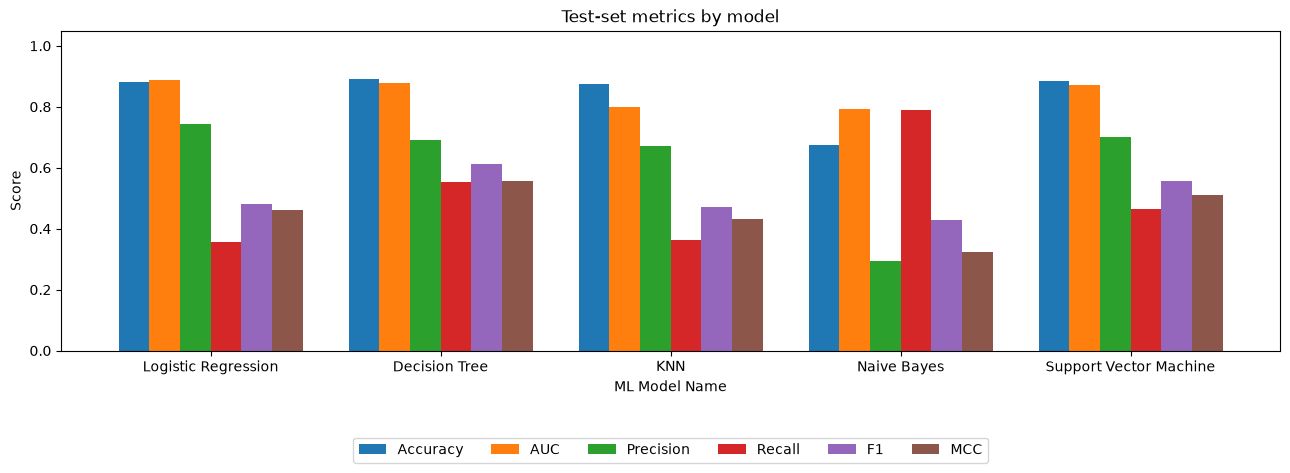

In [11]:
ax = results.plot.bar(figsize=(13, 5), width=0.8)
ax.set_ylim(0, 1.05); ax.set_ylabel("Score"); ax.set_title("Test-set metrics by model")
ax.legend(ncol=6, loc="upper center", bbox_to_anchor=(0.5, -0.25))
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

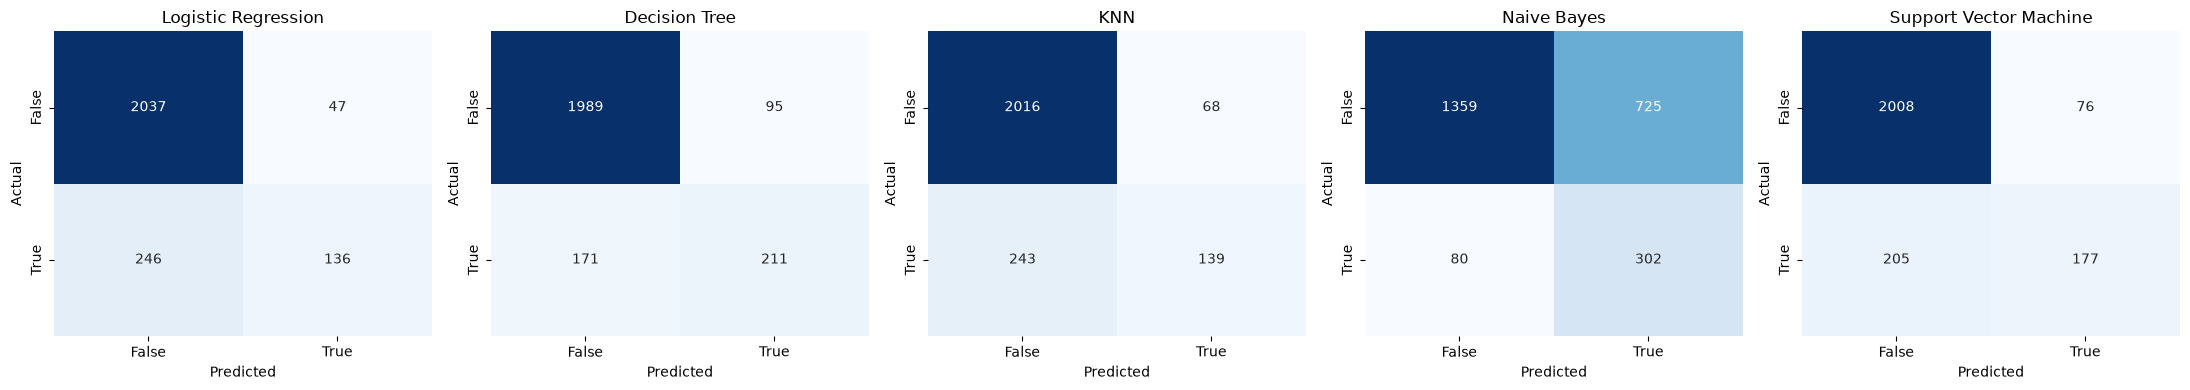

Classification report – Decision Tree (best MCC)

              precision    recall  f1-score   support

       False       0.92      0.95      0.94      2084
        True       0.69      0.55      0.61       382

    accuracy                           0.89      2466
   macro avg       0.81      0.75      0.78      2466
weighted avg       0.89      0.89      0.89      2466



In [12]:
fig, axes = plt.subplots(1, 5, figsize=(22, 4))
for ax, (name, y_pred) in zip(axes, predictions.items()):
    sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=class_names, yticklabels=class_names, ax=ax)
    ax.set_title(name); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout(); plt.show()

best = results["MCC"].idxmax()
print(f"Classification report – {best} (best MCC)\n")
print(classification_report(y_test, predictions[best], target_names=class_names, zero_division=0))

## 7. Save models, test data and metadata (used by the Streamlit app)

In [13]:
for name, pipe in fitted.items():
    joblib.dump(pipe, os.path.join(MODEL_DIR, name.lower().replace(" ", "_") + ".joblib"))
joblib.dump(label_enc, os.path.join(MODEL_DIR, "label_encoder.joblib"))
with open(os.path.join(MODEL_DIR, "metadata.json"), "w") as f:
    json.dump({"target": TARGET, "features": X.columns.tolist(), "classes": class_names}, f, indent=2)
results.to_csv(os.path.join(MODEL_DIR, "metrics.csv"))

test_df = X_test.copy()
test_df[TARGET] = label_enc.inverse_transform(y_test)
test_df.to_csv("test_data.csv", index=False)

print("Saved:", sorted(os.listdir(MODEL_DIR)))
print("test_data.csv:", test_df.shape)

Saved: ['decision_tree.joblib', 'knn.joblib', 'label_encoder.joblib', 'logistic_regression.joblib', 'metadata.json', 'metrics.csv', 'naive_bayes.joblib', 'support_vector_machine.joblib']
test_data.csv: (2466, 18)
